# Investigating Glacial and Interglacial Cycles with Python
**GEOG 202 | Guided in-class investigation (~75–90 minutes)**

**Big question:** How has the Earth's climate changed in the past and how can we relate that to what we have learned this semester?

### **Learning goals:** 
1) read and plot climate data 
2) connect eccentricity, obliquity, and precession to seasonal insolation; 
3) interpret CO₂ and benthic δ¹⁸O records; 
4) compare ~41-kyr and ~100-kyr variability.

### **Instructions:** 
Run code cells in order with **Shift + Enter**. Code is provided; your job is to experiment and explain. Write answers in the markdown response cells or on the print out. 

### Helpful notes:
**ka** means thousands of years before present.

___
## Before you begin: data files
This notebook uses provided datasets. Check to see that you have the following files in the `data` folder.

- `INSOLN.LA2004.BTL.100.csv` — orbital parameters
- `j_65north.csv` — 65°N insolation
- `antarctica2015co2composite.txt` — Antarctic CO₂ composite
- `LR04stack.csv` — LR04 benthic oxygen-isotope stack

<font color=blue>**Tip:**</font> If a cell reports `FileNotFoundError`, check the `data` folder before continuing.

___ 

### Python basics and importing the scientific python packages we will need
Python is a popular general-purpose computer language. It is human readable and has many pre-built code toolboxes that can turn it into a fast platform for math, data analysis, and visualiztion. 

Today, we will not focus on how to code using Python, but instead look at ways we can use it to look at past climates. 

We will utilize several libraries to help us do this by running the `import` command flowed by the open source library. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from scipy.interpolate import interp1d

___

## Controls, feedbacks, and measures of climate

Apart from internal causes (like humans) Earth's climate is thought to be largely controlled by the amount of light from the sun arriving on Earth, called **insolation**.

This is controlled by the position of the Earth relative to the sun, referred to as the orbital parameters of **eccentricity**, **obliquity**, and **precession**.

As we know from more recent history, **$\text{CO}_2$** can warm and cool the Earth by trapping the incoming heat from the sun.

We can measure Earth's climate (in terms of **temperature**) back through time using various **climate proxies**. One of the best is $\delta$$O_{18}$.

<img src="./figures/Orbital-parameters-milankovitch_cycles.jpg" width = 1200>

## Investigating climate cycles
The Earth's orbital parameters of ellipticity, obliquity and precession vary in predictable ways.  One commonly used model for variations in them over the last few hundred million years was published by Laskar et al. (2004; http://dx.doi.org/10.1051/0004-6361:20041335).  

> This solution has been improved...by using a direct integration of the gravitational equations for the orbital motion, and by improving the dissipative contributions, in particular in the evolution of the Earth–Moon System. The orbital solution has been used for the calibration of the Neogene period (Lourens et al.  [CITE]), and is expected to be used for age calibrations of paleoclimatic data over 40 to 50 Myr, eventually over the full Palaeogene period (65 Myr) with caution. Beyond this time span, the chaotic evolution of the orbits prevents a precise determination of the Earth's motion. However, the most regular components of the orbital solution could still be used over a much longer time span. - Laskar et al. (2004)

Let's take a look for the behavior of the last few million years using the data file from the Laskar et al. (2004) paper. 

## Import the Lasker orbital solution

<font color=goldenrod>**Code for you to write**</font>
- Read in the data `INSOLN.LA2004.BTL.100.csv` and save it as `orbital_cycles`

1. Age (ka)
   - Unit: ka stands for kilo-annum, meaning thousands of years before present (or relative to a specific model baseline).
   - Meaning: The time step of the row. For example, 0 is the present day, 1 is 1,000 years ago, 2 is 2,000 years ago, and so on.
   
2. Eccentricity
   - Unit: Dimensionless (no unit).
   - Meaning: Measures how much Earth's orbit around the Sun deviates from a perfect circle. A value of 0 is a perfect circle, while higher values mean a more elliptical (oval) orbit. The values hover around 0.016, which matches Earth's current low-eccentricity orbit.   

3. Obliquity
   - Unit: Radians (specifically, roughly 0.409 radians corresponds to Earth's axial tilt of about $23.44^\circ$).   
   - Meaning: Represents Earth's axial tilt relative to its orbital plane. It dictates the intensity of the seasons and fluctuates between roughly 0.386 and 0.427 radians ($22.1^\circ$ to $24.5^\circ$) over a 41,000-year cycle. 

In [2]:
orbital_cycles = pd.read_csv('data/INSOLN.LA2004.BTL.100.csv')
orbital_cycles.describe()

,Age (ka),Eccentricity,Obliquity,Precession
count,101001.000000,101001.000000,101001.000000,101001.000000
mean,50500.000000,0.027836,0.404392,3.140155
std,29156.621606,0.013255,0.008288,1.812224
min,0.000000,0.000106,0.382814,0.000039
25%,25250.000000,0.017686,0.397779,1.572261
50%,50500.000000,0.026889,0.404338,3.138744
75%,75750.000000,0.037304,0.410948,4.708932
max,101000.000000,0.066957,0.427330,6.283108


1. Age (ka)
   - Unit: ka stands for kilo-annum, meaning thousands of years before present (or relative to a specific model baseline).
   - Meaning: The time step of the row. For example, 0 is the present day, 1 is 1,000 years ago, 2 is 2,000 years ago, and so on.
   
2. Eccentricity
   - Unit: Dimensionless (no unit).
   - Meaning: Measures how much Earth's orbit around the Sun deviates from a perfect circle. A value of 0 is a perfect circle, while higher values mean a more elliptical (oval) orbit. The values hover around 0.016, which matches Earth's current low-eccentricity orbit.   

3. Obliquity
   - Unit: Radians (specifically, roughly 0.409 radians corresponds to Earth's axial tilt of about $23.44^\circ$).   
   - Meaning: Represents Earth's axial tilt relative to its orbital plane. It dictates the intensity of the seasons and fluctuates between roughly 0.386 and 0.427 radians ($22.1^\circ$ to $24.5^\circ$) over a 41,000-year cycle. 

4. Precession
   - Unit:
   - Meaning:  

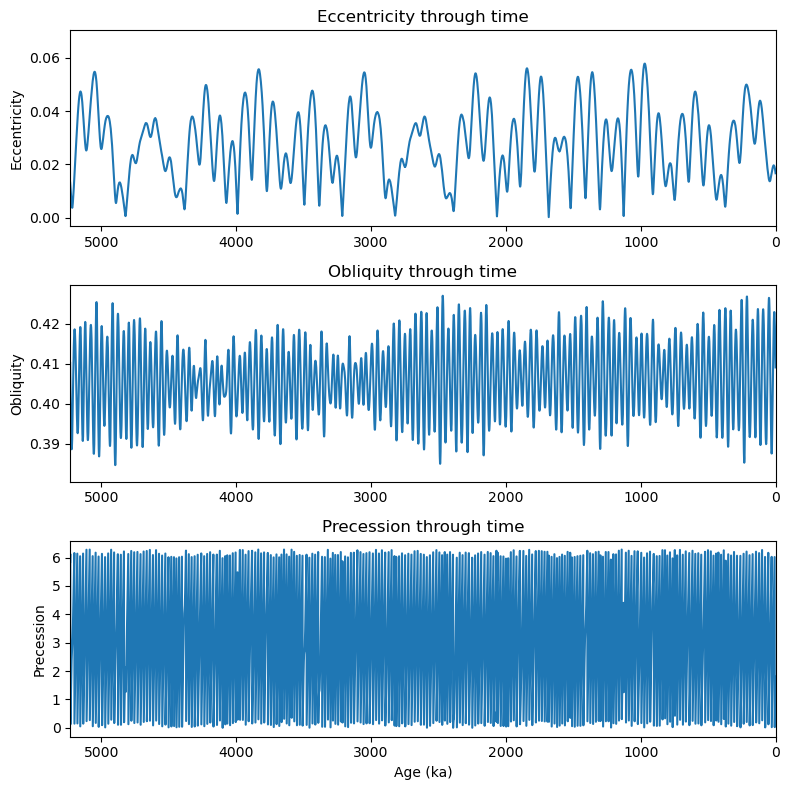

In [3]:
plt.figure(figsize=(8,8))

plt.subplot(3,1,1)
plt.plot(orbital_cycles['Age (ka)'],orbital_cycles['Eccentricity'])
plt.xlim(5230,0)
plt.ylabel('Eccentricity')
plt.title('Eccentricity through time')

plt.subplot(3,1,2)
plt.plot(orbital_cycles['Age (ka)'],orbital_cycles['Obliquity'])
plt.xlim(5230,0)
plt.ylabel('Obliquity')
plt.title('Obliquity through time')

plt.subplot(3,1,3)
plt.plot(orbital_cycles['Age (ka)'],orbital_cycles['Precession'])
plt.xlim(5230,0)
plt.ylabel('Precession')
plt.xlabel('Age (ka)')
plt.title('Precession through time')
plt.tight_layout()
plt.show()

# Trim the dataset
This dataset is a little long. We will focus on the lat 1 million years (1000 kyr)

In [5]:
#Filter the dataset to only the past 1000 ka
orbital_cycles_1Myr = orbital_cycles[orbital_cycles['Age (ka)']<=1000]
orbital_cycles_1Myr.describe()

,Age (ka),Eccentricity,Obliquity,Precession
count,1001.000000,1001.000000,1001.000000,1001.000000
mean,500.000000,0.028139,0.407353,3.152272
std,289.108111,0.012795,0.009761,1.821187
min,0.000000,0.004155,0.385302,0.014260
25%,250.000000,0.016948,0.399126,1.580712
50%,500.000000,0.028318,0.407717,3.162161
75%,750.000000,0.037569,0.415531,4.737278
max,1000.000000,0.057815,0.426813,6.270303


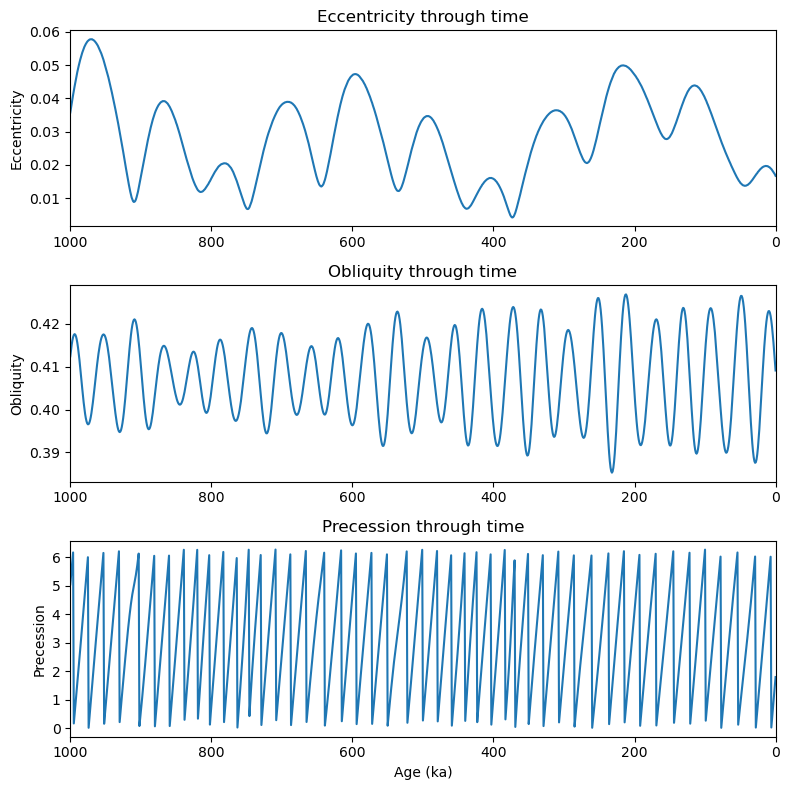

In [9]:
plt.figure(figsize=(8,8))

plt.subplot(3,1,1)
plt.plot(orbital_cycles_1Myr['Age (ka)'],orbital_cycles_1Myr['Eccentricity'])
plt.xlim(1000,0)
plt.ylabel('Eccentricity')
plt.title('Eccentricity through time')

plt.subplot(3,1,2)
plt.plot(orbital_cycles_1Myr['Age (ka)'],orbital_cycles_1Myr['Obliquity'])
plt.xlim(1000,0)
plt.ylabel('Obliquity')
plt.title('Obliquity through time')

plt.subplot(3,1,3)
plt.plot(orbital_cycles_1Myr['Age (ka)'],orbital_cycles_1Myr['Precession'])
plt.xlim(1000,0)
plt.ylabel('Precession')
plt.xlabel('Age (ka)')
plt.title('Precession through time')
plt.tight_layout()
plt.show()

Let's investigate the periodicity of these signals.

<font color=goldenrod>**Code for you to write**</font>
- Use `signal.periodogram` to calculate the frequencies and powers for the `Eccentricity` series
- Use `signal.periodogram` to calculate the frequencies and powers for the `Obliquity` series
- Use `signal.periodogram` to calculate the frequencies and powers for the `Precession` series
- As three subplots, plot the spectra for each of the Eccentricity, Obliquity, and Precession
- Add x and y labels and a title

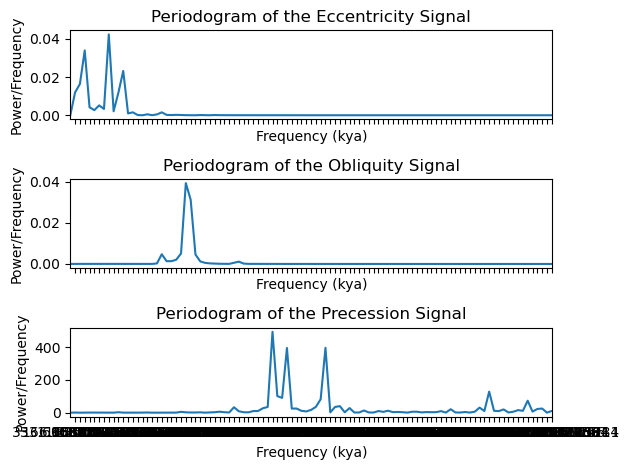

In [11]:
#Save the frequencies and power in the insolation time series to new variables
frequency_ecc, power_ecc = signal.periodogram(orbital_cycles_1Myr['Eccentricity'], 1)
frequency_obl, power_obl = signal.periodogram(orbital_cycles_1Myr['Obliquity'], 1)
frequency_prec, power_prec = signal.periodogram(orbital_cycles_1Myr['Precession'], 1)

#Plot the power (y) in each frequency (x)
#Plot times series and spectrum

fig, axes = plt.subplots(3,1, sharex=True)

labels = ['Eccentricity', 'Obliquity', 'Precession']
frequencies = [frequency_ecc, frequency_obl, frequency_prec]
powers = [power_ecc, power_obl, power_prec]

# converting to frequncy of years


for i, ax in enumerate(axes):
    axes[i].plot(frequencies[i], powers[i])
    axes[i].set_xlabel('Frequency (kya)')
    axes[i].set_ylabel('Power/Frequency')
    axes[i].set_title(f'Periodogram of the {labels[i]} Signal')


xticks = frequencies[i][1:]
xlabels = 1/frequencies[1][1:]
plt.xticks(xticks, xlabels)
plt.xlim(0,0.1)
plt.tight_layout()
plt.show()